# 00 — Audio fundamentals

Before building any model, I want to understand what the input actually is.
This notebook loads 4 NSynth notes **at the same pitch (MIDI 60 = C4, ~262 Hz) and velocity**, from
different instrument families. Fixing pitch and velocity means the visible differences between them
are (mostly) **timbre** — which is exactly what the classifier has to learn.

Three representations, each built from the previous one:
1. **Waveform** — the raw signal.
2. **STFT spectrogram** — energy per frequency over time.
3. **Log-mel spectrogram** — the STFT warped to a perceptual frequency scale and compressed in amplitude. This is the input to the CNN later.

In [1]:
import json
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display

DATA = Path("../data/raw/nsynth-valid")
SR = 16_000  # NSynth sample rate -> Nyquist frequency = 8 kHz

meta = json.loads((DATA / "examples.json").read_text())
print(f"{len(meta)} notes in the valid split")

# Hand-picked: all acoustic, pitch 60 (C4), velocity 100.
# Chosen for contrast: two sustained instruments (brass, reed) vs two that decay (guitar, mallet).
# Note: the valid split has no *acoustic* flute at this pitch -- very few physical instruments per family here.
picked = {
    "brass": "brass_acoustic_015-060-100",
    "reed": "reed_acoustic_011-060-100",
    "guitar": "guitar_acoustic_014-060-100",
    "mallet": "mallet_acoustic_056-060-100",
}
assert all(meta[n]["pitch"] == 60 and meta[n]["instrument_source_str"] == "acoustic" for n in picked.values())
picked

12678 notes in the valid split


{'brass': 'brass_acoustic_015-060-100',
 'reed': 'reed_acoustic_011-060-100',
 'guitar': 'guitar_acoustic_014-060-100',
 'mallet': 'mallet_acoustic_056-060-100'}

In [2]:
signals = {fam: librosa.load(DATA / "audio" / f"{name}.wav", sr=None)[0] for fam, name in picked.items()}
for fam, y in signals.items():
    print(f"{fam:8s} samples={len(y)}  duration={len(y)/SR:.2f}s  source={meta[picked[fam]]['instrument_source_str']}")
    display(Audio(y, rate=SR))

brass    samples=64000  duration=4.00s  source=acoustic


reed     samples=64000  duration=4.00s  source=acoustic


guitar   samples=64000  duration=4.00s  source=acoustic


mallet   samples=64000  duration=4.00s  source=acoustic


## 1. Waveform

The waveform is air pressure (as measured by a microphone) sampled 16,000 times per second.
One 4-second note is a vector of 64,000 numbers.

What it shows well: **the amplitude envelope** — attack, sustain, decay. Brass and reed hold their energy
until the note is released at 3 s (NSynth notes are held for 3 s, then 1 s of release); the guitar decays
gradually; the mallet dies out within a fraction of a second.

What it hides: **which frequencies are present**. Zooming into a few milliseconds shows a periodic shape
(period ≈ 1/262 Hz ≈ 3.8 ms), and the *shape* of that period encodes timbre — but it is not readable by eye,
and it shifts with phase. That is why we move to the frequency domain.

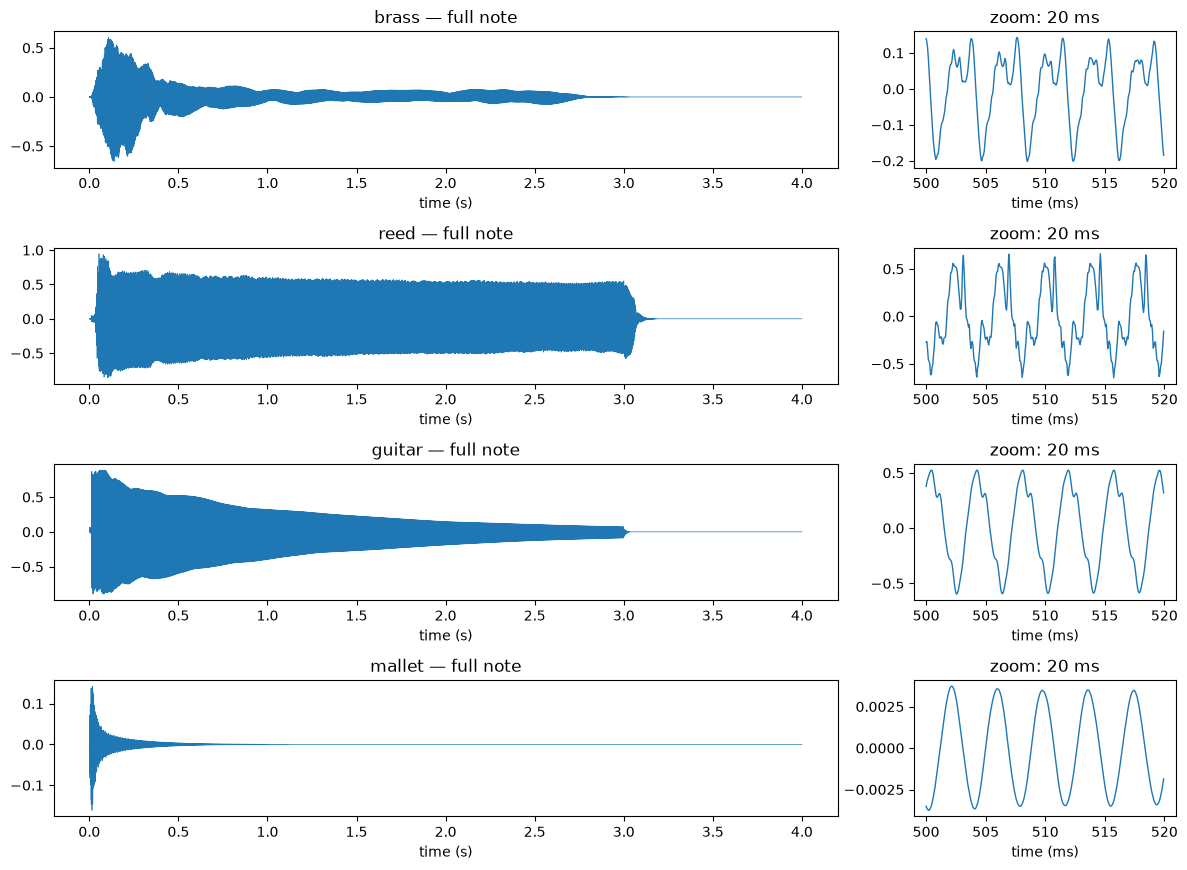

In [3]:
fig, axes = plt.subplots(len(signals), 2, figsize=(12, 2.2 * len(signals)), gridspec_kw={"width_ratios": [3, 1]})
for (fam, y), (ax_full, ax_zoom) in zip(signals.items(), axes):
    t = np.arange(len(y)) / SR
    ax_full.plot(t, y, lw=0.5)
    ax_full.set(title=f"{fam} — full note", xlabel="time (s)")
    start = int(0.5 * SR)  # 20 ms window starting at 0.5 s
    seg = slice(start, start + int(0.02 * SR))
    ax_zoom.plot(t[seg] * 1000, y[seg], lw=1)
    ax_zoom.set(title="zoom: 20 ms", xlabel="time (ms)")
plt.tight_layout()

## 2. STFT (Short-Time Fourier Transform)

The Fourier transform says *which frequencies* a signal contains, but over the whole signal, so all timing is lost.
The STFT slides a short **window** along the signal and computes a Fourier transform per window:

- `n_fft = 1024` samples → window of 64 ms → frequency resolution 16000/1024 ≈ **15.6 Hz** per bin.
- `hop_length = 256` samples → a new frame every **16 ms**.

**Time–frequency trade-off:** a longer window gives finer frequency resolution but blurs fast events (attacks);
a shorter window does the opposite. You can't have both. 64 ms is enough to separate the harmonics of a 262 Hz note
(spaced 262 Hz apart) while still roughly capturing the attack.

The magnitude is shown in **dB** (log scale). In linear amplitude, the fundamental dominates and the upper
harmonics are almost invisible — see the comparison in the first row.

What to look for: horizontal lines at 262, 524, 786, ... Hz are the **harmonics**. The pattern of their
relative strengths, and how each one decays over time, is a large part of what we call timbre.

STFT shape (freq bins, frames): (513, 251)


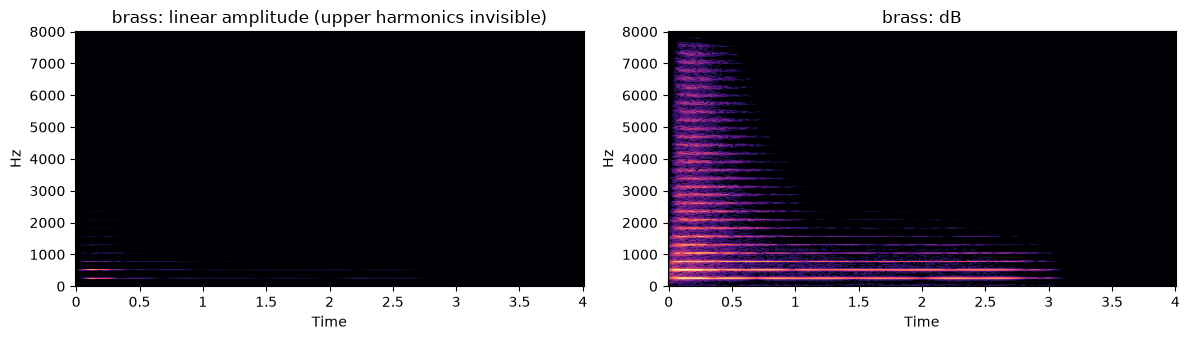

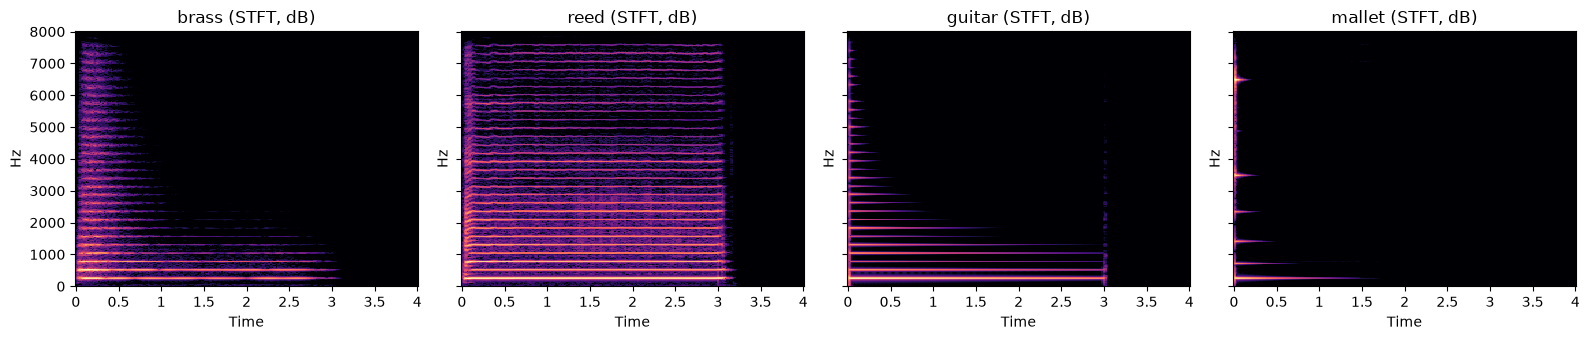

In [4]:
N_FFT, HOP = 1024, 256
stfts = {fam: np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP)) for fam, y in signals.items()}
first = next(iter(stfts))
print("STFT shape (freq bins, frames):", stfts[first].shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
librosa.display.specshow(stfts[first], sr=SR, hop_length=HOP, x_axis="time", y_axis="linear", ax=axes[0])
axes[0].set(title=f"{first}: linear amplitude (upper harmonics invisible)")
librosa.display.specshow(librosa.amplitude_to_db(stfts[first], ref=np.max), sr=SR, hop_length=HOP,
                         x_axis="time", y_axis="linear", ax=axes[1])
axes[1].set(title=f"{first}: dB")
plt.tight_layout()

fig, axes = plt.subplots(1, len(stfts), figsize=(4 * len(stfts), 3.5), sharey=True)
for ax, (fam, S) in zip(axes, stfts.items()):
    librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max), sr=SR, hop_length=HOP,
                             x_axis="time", y_axis="linear", ax=ax)
    ax.set(title=f"{fam} (STFT, dB)")
plt.tight_layout()

## 3. Mel scale and log compression

The STFT has 513 linearly spaced bins. Two problems:

**Frequency axis — why mel.** Pitch perception is roughly logarithmic: going 100→200 Hz and 1000→2000 Hz are both
one octave. In a linear STFT, high frequencies take up most of the bins while carrying less perceptually relevant
detail per Hz. The **mel filterbank** sums STFT bins with triangular filters that are narrow at low frequencies and
wide at high frequencies. Result: 513 bins → 128 mel bands, more resolution where it matters, a smaller input.

*Caveat:* mel is a model of *human* perception. It's a good prior, not a law — a model doesn't have ears, and
fine high-frequency detail is lost. That's a design choice to remember when analysing errors.

**Amplitude axis — why log.** Audio energy spans many orders of magnitude (~60–100 dB). Without the log,
a few loud bins dominate every gradient and every distance. The log also turns *multiplicative* changes
(the same note played louder = everything scaled by a gain) into *additive* shifts, which are much easier for
a linear model or a conv layer with a bias to handle.

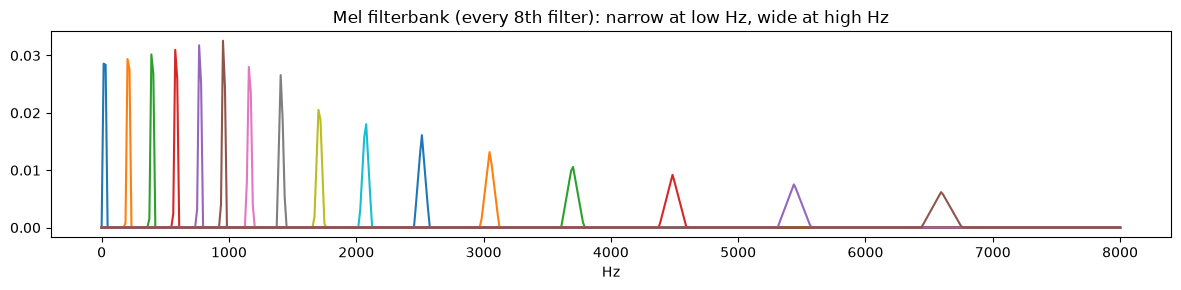

In [5]:
N_MELS = 128
mel_fb = librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS)
fig, ax = plt.subplots(figsize=(12, 3))
freqs = np.linspace(0, SR / 2, mel_fb.shape[1])
for i in range(0, N_MELS, 8):  # plot every 8th filter for readability
    ax.plot(freqs, mel_fb[i])
ax.set(title="Mel filterbank (every 8th filter): narrow at low Hz, wide at high Hz", xlabel="Hz")
plt.tight_layout()

log-mel shape (mel bands, frames): (128, 251)


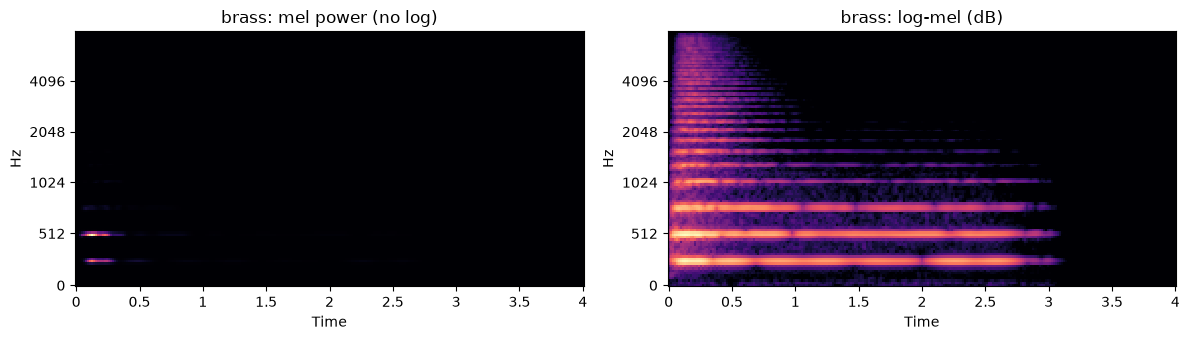

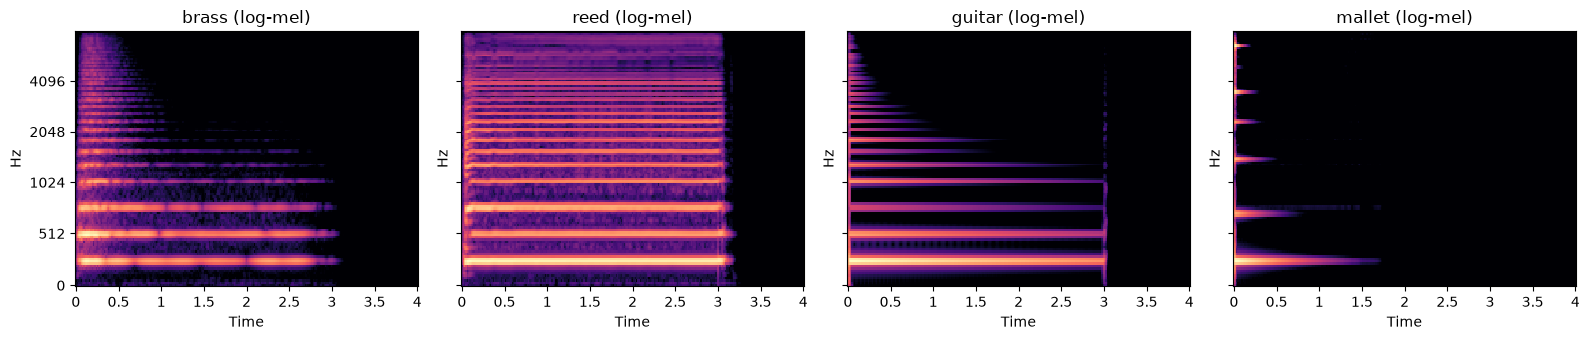

In [6]:
mels = {fam: librosa.feature.melspectrogram(S=S**2, sr=SR, n_mels=N_MELS) for fam, S in stfts.items()}
logmels = {fam: librosa.power_to_db(M, ref=np.max) for fam, M in mels.items()}
print("log-mel shape (mel bands, frames):", logmels[first].shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
librosa.display.specshow(mels[first], sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=axes[0])
axes[0].set(title=f"{first}: mel power (no log)")
librosa.display.specshow(logmels[first], sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=axes[1])
axes[1].set(title=f"{first}: log-mel (dB)")
plt.tight_layout()

fig, axes = plt.subplots(1, len(logmels), figsize=(4 * len(logmels), 3.5), sharey=True)
for ax, (fam, L) in zip(axes, logmels.items()):
    librosa.display.specshow(L, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax)
    ax.set(title=f"{fam} (log-mel)")
plt.tight_layout()

## What the plots show (same pitch, same velocity, different family)

- **Envelope:** reed holds steady until release at 3 s; brass has a loud, bright attack and then settles;
  guitar decays over ~3 s; mallet is gone in well under a second.
- **Brightness over time:** brass has energy up to ~7 kHz only during the first ~0.5 s, then mostly below 2 kHz.
  Reed keeps many strong harmonics for the whole note.
- **Harmonic vs. inharmonic:** measuring the strongest peaks in the first 150 ms (cell below), the guitar's partials
  sit at integer multiples of f0 (ratios 1, 2, 4, 5, 7, 11). The mallet's sit at **1, 2.76, 5.40, 8.93, 13.35**,
  which matches the theoretical modes of a freely vibrating bar. Same "note", physically very different spectra.

None of these cues is a single feature; the classifier has to combine spectral shape *and* how it evolves in time.

In [7]:
from scipy.signal import find_peaks

def partial_ratios(y, f0=261.6, dur=0.15, n_peaks=6):
    seg = y[: int(dur * SR)] * np.hanning(int(dur * SR))
    spec = np.abs(np.fft.rfft(seg, n=1 << 16))
    freqs = np.fft.rfftfreq(1 << 16, 1 / SR)
    db = 20 * np.log10(spec / spec.max() + 1e-12)
    peaks, _ = find_peaks(db, height=-50, distance=200)
    peaks = np.sort(peaks[np.argsort(db[peaks])[::-1][:n_peaks]])
    return np.round(freqs[peaks] / f0, 2)

for fam in ["guitar", "mallet"]:
    print(f"{fam:7s} partial / f0:", partial_ratios(signals[fam]))

guitar  partial / f0: [ 1.    2.    3.99  4.99  7.   11.03]
mallet  partial / f0: [ 1.    2.76  5.4   8.93 13.35 24.82]


## Takeaways for the next phases

- A 4 s note becomes a **128 × 251 log-mel "image"**. That is the CNN input in Phase 3.
- Unlike a photo, the two axes are **not equivalent**: shifting along time keeps the meaning (same sound, later),
  shifting along frequency changes it (different pitch / different timbre). Worth keeping in mind when
  choosing kernels, pooling and augmentation.
- Same pitch, different family → clearly different harmonic patterns and envelopes. That's the signal we hope
  both models will find.
- The MFCC baseline (Phase 2) is computed *from* the log-mel: a DCT over the mel axis, keeping the first ~20
  coefficients — a compact description of the spectral envelope.